# Assignment 2

> Module: production<br>
> Assignment: 2<br>
> Name: Chun-Yuan Chen

In this assigment, we will work with the *Forest Fire* data set. Please download the data from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/162/forest+fires). Extract the data files into the subdirectory: `../data/fires/` (relative to `./05_src/`).

## Objective

+ The model objective is to predict the area affected by forest fires given the features set. 
+ The objective of this exercise is to assess your ability to construct and evaluate model pipelines.
+ Please note: the instructions are not meant to be 100% prescriptive, but instead they are a set of minimum requirements. If you find predictive performance gains by applying additional steps, by all means show them. 

## Variable Description

From the description file contained in the archive (`forestfires.names`), we obtain the following variable descriptions:

1. X - x-axis spatial coordinate within the Montesinho park map: 1 to 9
2. Y - y-axis spatial coordinate within the Montesinho park map: 2 to 9
3. month - month of the year: "jan" to "dec" 
4. day - day of the week: "mon" to "sun"
5. FFMC - FFMC index from the FWI system: 18.7 to 96.20
6. DMC - DMC index from the FWI system: 1.1 to 291.3 
7. DC - DC index from the FWI system: 7.9 to 860.6 
8. ISI - ISI index from the FWI system: 0.0 to 56.10
9. temp - temperature in Celsius degrees: 2.2 to 33.30
10. RH - relative humidity in %: 15.0 to 100
11. wind - wind speed in km/h: 0.40 to 9.40 
12. rain - outside rain in mm/m2 : 0.0 to 6.4 
13. area - the burned area of the forest (in ha): 0.00 to 1090.84 









### Specific Tasks

+ Construct four model pipelines, out of combinations of the following components:

    + Preprocessors:

        - A simple processor that only scales numeric variables and recodes categorical variables.
        - A transformation preprocessor that scales numeric variables and applies a non-linear transformation.
    
    + Regressor:

        - A baseline regressor, which could be a [K-nearest neighbours model]() or a linear model like [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) or [Ridge Regressors](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ridge_regression.html).
        - An advanced regressor of your choice (e.g., Bagging, Boosting, SVR, etc.). TIP: select a tree-based method such that it does not take too long to run SHAP further below. 

+ Evaluate tune and evaluate each of the four model pipelines. 

    - Select a [performance metric](https://scikit-learn.org/stable/modules/linear_model.html) out of the following options: explained variance, max error, root mean squared error (RMSE), mean absolute error (MAE), r-squared.
    - *TIPS*: 
    
        * Out of the suggested metrics above, [some are correlation metrics, but this is a prediction problem](https://www.tmwr.org/performance#performance). Choose wisely (and don't choose the incorrect options.) 

+ Select the best-performing model and explain its predictions.

    - Provide local explanations.
    - Obtain global explanations and recommend a variable selection strategy.

+ Export your model as a pickle file.


You can work on the Jupyter notebook, as this experiment is fairly short (no need to use sacred). 

# Load the data

Place the files in the ../../05_src/data/fires/ directory and load the appropriate file. 

In [1]:
# Load the libraries as required.
%load_ext dotenv
%dotenv
import os
import sys
import pandas as pd
import numpy as np
from glob import glob
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score, GridSearchCV, train_test_split
from sklearn.ensemble import RandomForestRegressor
import pickle
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Load data
columns = [
    'coord_x', 'coord_y', 'month', 'day', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain', 'area' 
]
fires_dt = (pd.read_csv('../../05_src/data/fires/forestfires.csv', header = 0, names = columns))
fires_dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   coord_x  517 non-null    int64  
 1   coord_y  517 non-null    int64  
 2   month    517 non-null    object 
 3   day      517 non-null    object 
 4   ffmc     517 non-null    float64
 5   dmc      517 non-null    float64
 6   dc       517 non-null    float64
 7   isi      517 non-null    float64
 8   temp     517 non-null    float64
 9   rh       517 non-null    int64  
 10  wind     517 non-null    float64
 11  rain     517 non-null    float64
 12  area     517 non-null    float64
dtypes: float64(8), int64(3), object(2)
memory usage: 52.6+ KB


# Get X and Y

Create the features data frame and target data.

### Features

In [3]:
# CYC: Unprocessed data for features of interest.
features = fires_dt.drop(columns=['area'])

In [4]:
# CYC: Instead of using 'coord_x' and 'coord_y' separately, I bundled them into a coordinate pair and treated it as a categorical feature for later use in models.
features['coord_pair'] = (features['coord_x'].astype(str) + ', ' + features['coord_y'].astype(str)).astype('category') 
features = features.drop(columns=['coord_x', 'coord_y'])

In [5]:
# CYC: Instead of using the original 'month' and 'day', I reclassified their values into new categories, renaming them as 'season' and 'day_type', respectively.
features['season'] = features['month'].replace({
    'mar': 'spring', 'apr': 'spring', 'may': 'spring',
    'jun': 'summer', 'jul': 'summer', 'aug': 'summer',
    'sep': 'autumn', 'oct': 'autumn', 'nov': 'autumn',
    'dec': 'winter', 'jan': 'winter', 'feb': 'winter'
}).astype('category')

features['day_type'] = features['day'].replace({
    'mon': 'weekday', 'tue': 'weekday', 'wed': 'weekday', 'thu': 'weekday', 'fri': 'weekday',
    'sat': 'weekend', 'sun': 'weekend'
}).astype('category')

features = features.drop(columns=['month', 'day'])

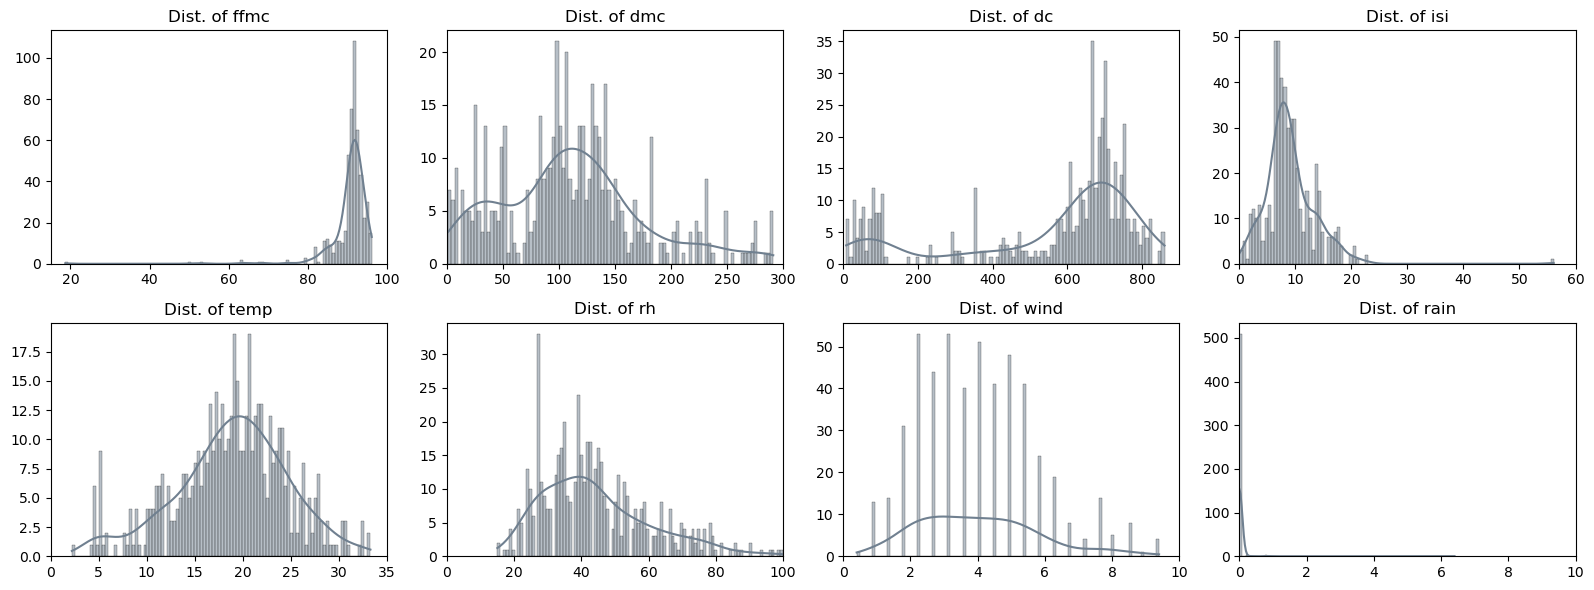

In [6]:
# CYC: I added this chunk of code to get an initial sense of the numeric features.
# Reference: https://stackoverflow.com/questions/38727364/how-would-i-iterate-over-a-list-of-files-and-plot-them-as-subplots-on-a-single-f

features_num = features.select_dtypes(include=['int64', 'float64']).columns
features_xaxis = {'ffmc': (15, 100), 'dmc': (0, 300), 'dc': (0, 900), 'isi': (0, 60), 'temp': (0, 35), 'rh': (0, 100), 'wind': (0, 10), 'rain': (0, 10)}

plt.figure(figsize=(16, 6))

for index, variable in enumerate(features_num, 1):
    plt.subplot(2, 4, index)
    sns.histplot(fires_dt[variable], kde=True, bins=100, color='slategray')
    plt.title(f'Dist. of {variable}')
    plt.xlabel('')
    plt.ylabel('')
    if variable in features_xaxis:
        plt.xlim(features_xaxis[variable])

plt.tight_layout()
plt.show()

In [7]:
# CYC: I added this chunk of code to get an initial sense of the categorical features.
# Reference: https://stackoverflow.com/questions/38783027/jupyter-notebook-display-two-pandas-tables-side-by-side

features_cat = features.select_dtypes(include=['object', 'category']).columns

features_tables = []

for variable in features_cat:
    freq = pd.DataFrame({
        'Count': features[variable].value_counts(),
        '%': features[variable].value_counts(normalize=True).round(3)*100
    })
    freq_html = f"<div style='display:inline-block; vertical-align:top; margin-right:60px;'>"
    freq_html += f"<h3> Freq. table for '{variable}':</h3>{freq.to_html()}"
    freq_html += "</div>"
    features_tables.append(freq_html)

display(HTML(''.join(features_tables)))

,Count,%
coord_pair,,
"8, 6",52,10.1
"6, 5",49,9.5
"7, 4",45,8.7
"3, 4",43,8.3
"4, 4",36,7.0
"2, 4",27,5.2
"4, 5",25,4.8
"2, 2",25,4.8
"6, 3",25,4.8


### Outcome

In [8]:
# CYC: Unprocessed data for the outcome.
outcome = fires_dt['area']
outcome

0       0.00
1       0.00
2       0.00
3       0.00
4       0.00
       ...  
512     6.44
513    54.29
514    11.16
515     0.00
516     0.00
Name: area, Length: 517, dtype: float64

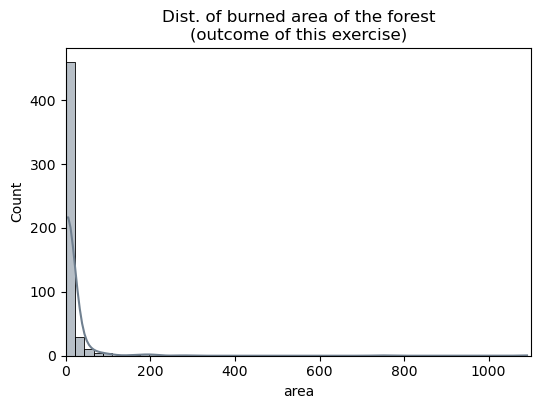

In [9]:
# CYC: I added this chunk of code to get an initial sense of the original outcome.
plt.figure(figsize=(6, 4))
sns.histplot(fires_dt['area'], kde=True, bins=50, color='slategray')
plt.title('Dist. of burned area of the forest\n(outcome of this exercise)')
plt.xlim(0, 1100)
plt.show()

# Preprocessing

Create two [Column Transformers](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), called preproc1 and preproc2, with the following guidelines:

- Numerical variables

    * (Preproc 1 and 2) Scaling: use a scaling method of your choice (Standard, Robust, Min-Max). 
    * Preproc 2 only: 
        
        + Choose a transformation for any of your input variables (or several of them). Evaluate if this transformation is convenient.
        + The choice of scaler is up to you.

- Categorical variables: 
    
    * (Preproc 1 and 2) Apply [one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) where appropriate.


+ The only difference between preproc1 and preproc2 is the non-linear transformation of the numerical variables.
    


### Preproc 1

Create preproc1 below.

+ Numeric: scaled variables, no other transforms.
+ Categorical: one-hot encoding.

In [10]:
pipe_ssc = Pipeline([
    ('ssc', StandardScaler())
])

pipe_ohe = Pipeline([
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

preproc1 = ColumnTransformer([
    ('ssc_num', pipe_ssc, features_num),
    ('ohe_cat', pipe_ohe, features_cat)
], remainder='passthrough')

preproc1

ColumnTransformer(remainder='passthrough',
                  transformers=[('ssc_num',
                                 Pipeline(steps=[('ssc', StandardScaler())]),
                                 Index(['ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain'], dtype='object')),
                                ('ohe_cat',
                                 Pipeline(steps=[('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['coord_pair', 'season', 'day_type'], dtype='object'))])

### Preproc 2

Create preproc1 below.

+ Numeric: scaled variables, non-linear transformation to one or more variables.
+ Categorical: one-hot encoding.

In [11]:
pipe_log_ssc = Pipeline([
    ('log', FunctionTransformer(np.log1p, validate=True)),
    ('ssc', StandardScaler())
])

preproc2 = ColumnTransformer([
    ('log_ssc_num', pipe_log_ssc, features_num),
    ('ohe_cat', pipe_ohe, features_cat)
], remainder='passthrough')

preproc2

ColumnTransformer(remainder='passthrough',
                  transformers=[('log_ssc_num',
                                 Pipeline(steps=[('log',
                                                  FunctionTransformer(func=<ufunc 'log1p'>,
                                                                      validate=True)),
                                                 ('ssc', StandardScaler())]),
                                 Index(['ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain'], dtype='object')),
                                ('ohe_cat',
                                 Pipeline(steps=[('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['coord_pair', 'season', 'day_type'], dtype='object'))])

## Model Pipeline


Create a [model pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html): 

+ Add a step labelled `preprocessing` and assign the Column Transformer from the previous section.
+ Add a step labelled `regressor` and assign a regression model to it. 

## Regressor

+ Use a regression model to perform a prediction. 

    - Choose a baseline regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Choose a more advance regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Both model choices are up to you, feel free to experiment.

In [12]:
# Pipeline A = preproc1 + baseline (Ridge regression)
pipeline_A = Pipeline([
    ('preprocessing', preproc1),
    ('regressor', Ridge())
])

pipeline_A

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('ssc_num',
                                                  Pipeline(steps=[('ssc',
                                                                   StandardScaler())]),
                                                  Index(['ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain'], dtype='object')),
                                                 ('ohe_cat',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['coord_pair', 'season', 'day_type'], dtype='object'))])),
                ('regressor', Ridge())])

In [13]:
# Pipeline B = preproc2 + baseline (Ridge regression)
pipeline_B = Pipeline([
    ('preprocessing', preproc2),
    ('regressor', Ridge())
])

pipeline_B

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('log_ssc_num',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>,
                                                                                       validate=True)),
                                                                  ('ssc',
                                                                   StandardScaler())]),
                                                  Index(['ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain'], dtype='object')),
                                                 ('ohe_cat',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['coord_pair', 'season', 'day_type'], dtype='object'))])),
                ('regressor', Ridge())])

In [14]:
# Pipeline C = preproc1 + advanced model (random forest)
pipeline_C = Pipeline([
    ('preprocessing', preproc1),
    ('regressor', RandomForestRegressor(random_state=68))
])

pipeline_C

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('ssc_num',
                                                  Pipeline(steps=[('ssc',
                                                                   StandardScaler())]),
                                                  Index(['ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain'], dtype='object')),
                                                 ('ohe_cat',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['coord_pair', 'season', 'day_type'], dtype='object'))])),
                ('regressor', RandomForestRegressor(random_state=68))])

In [15]:
# Pipeline D = preproc2 + advanced model (random forest)
pipeline_D = Pipeline([
    ('preprocessing', preproc2),
    ('regressor', RandomForestRegressor(random_state=68))
])

pipeline_D

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('log_ssc_num',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>,
                                                                                       validate=True)),
                                                                  ('ssc',
                                                                   StandardScaler())]),
                                                  Index(['ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain'], dtype='object')),
                                                 ('ohe_cat',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['coord_pair', 'season', 'day_type'], dtype='object'))])),
                ('regressor', RandomForestRegressor(random_state=68))])

# Tune Hyperparams

+ Perform GridSearch on each of the four pipelines. 
+ Tune at least one hyperparameter per pipeline.
+ Experiment with at least four value combinations per pipeline.

In [16]:
features_train, features_test, outcome_train, outcome_test = train_test_split(features, outcome, test_size = 0.3, random_state = 68)

### Pipeline A

In [17]:
# Pipeline A
# Reference: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

param_grid_A = {
    'regressor__alpha': [0.05, 0.10, 0.50, 5.00, 50.0, 100.0, 150.0, 200.0, 250.0]
}
res_grid_A = GridSearchCV(
    estimator=pipeline_A, 
    param_grid=param_grid_A, 
    scoring = 'neg_mean_squared_error', 
    cv = 5,
    refit = True)

res_grid_A.fit(features_train, outcome_train)

print(res_grid_A.best_params_)
print(-res_grid_A.best_score_)

{'regressor__alpha': 250.0}
5223.238240485375


In [18]:
res_grid_A.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('ssc_num',
                                                  Pipeline(steps=[('ssc',
                                                                   StandardScaler())]),
                                                  Index(['ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain'], dtype='object')),
                                                 ('ohe_cat',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['coord_pair', 'season', 'day_type'], dtype='object'))])),
                ('regressor', Ridge(alpha=250.0))])

In [19]:
A_outcome_pred = res_grid_A.best_estimator_.predict(features_test)
A_mse_test = mean_squared_error(outcome_test, A_outcome_pred)
print("Test MSE:", A_mse_test)

Test MSE: 1403.6585413869252


### Pipeline B

In [20]:
# Pipeline B
# Reference: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

param_grid_B = {
    'regressor__alpha': [0.05, 0.10, 0.50, 5.00, 50.0, 100.0, 150.0, 200.0, 250.0]
}
res_grid_B = GridSearchCV(
    estimator=pipeline_B, 
    param_grid=param_grid_B, 
    scoring = 'neg_mean_squared_error', 
    cv = 5,
    refit = True)

res_grid_B.fit(features_train, outcome_train)

print(res_grid_B.best_params_)
print(-res_grid_B.best_score_)

{'regressor__alpha': 250.0}
5216.3025885655325


In [21]:
res_grid_B.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('log_ssc_num',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>,
                                                                                       validate=True)),
                                                                  ('ssc',
                                                                   StandardScaler())]),
                                                  Index(['ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain'], dtype='object')),
                                                 ('ohe_cat',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['coord_pair', 'season', 'day_type'], dtype='object'))])),
                ('regressor', Ridge(alpha=250.0))])

In [22]:
B_outcome_pred = res_grid_B.best_estimator_.predict(features_test)
B_mse_test = mean_squared_error(outcome_test, B_outcome_pred)
print("Test MSE:", B_mse_test)

Test MSE: 1410.6150762740774


### Pipeline C

In [23]:
# Pipeline C
# Reference: https://medium.com/@kalpit.sharma/mastering-random-forest-hyperparameter-tuning-for-enhanced-machine-learning-models-2d1a8c6c426f

param_grid_C = {
    'regressor__n_estimators': [50, 100, 150],
    'regressor__max_depth': [10, 30, 50]
}

res_grid_C = GridSearchCV(
    estimator=pipeline_C,
    param_grid=param_grid_C,
    scoring='neg_mean_squared_error',
    cv=5,
    refit=True
)

res_grid_C.fit(features_train, outcome_train)

print(res_grid_C.best_params_)
print(-res_grid_C.best_score_)

{'regressor__max_depth': 30, 'regressor__n_estimators': 100}
7128.236304491128


In [24]:
res_grid_C.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('ssc_num',
                                                  Pipeline(steps=[('ssc',
                                                                   StandardScaler())]),
                                                  Index(['ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain'], dtype='object')),
                                                 ('ohe_cat',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['coord_pair', 'season', 'day_type'], dtype='object'))])),
                ('regressor',
                 RandomForestRegressor(max_depth=30, random_state=68))])

In [25]:
C_outcome_pred = res_grid_C.best_estimator_.predict(features_test)
C_mse_test = mean_squared_error(outcome_test, C_outcome_pred)
print("Test MSE:", C_mse_test)

Test MSE: 2838.6426718131943


### Pipeline D

In [26]:
# Pipeline D
# Reference: https://medium.com/@kalpit.sharma/mastering-random-forest-hyperparameter-tuning-for-enhanced-machine-learning-models-2d1a8c6c426f

param_grid_D= {
    'regressor__n_estimators': [50, 100, 150],
    'regressor__max_depth': [10, 30, 50]
}

res_grid_D = GridSearchCV(
    estimator=pipeline_D,
    param_grid=param_grid_D,
    scoring='neg_mean_squared_error',
    cv=5,
    refit=True
)

res_grid_D.fit(features_train, outcome_train)

print(res_grid_D.best_params_)
print(-res_grid_D.best_score_)

{'regressor__max_depth': 30, 'regressor__n_estimators': 100}
6525.473565922788


In [27]:
res_grid_D.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('log_ssc_num',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>,
                                                                                       validate=True)),
                                                                  ('ssc',
                                                                   StandardScaler())]),
                                                  Index(['ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain'], dtype='object')),
                                                 ('ohe_cat',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['coord_pair', 'season', 'day_type'], dtype='object'))])),
                ('regressor',
                 RandomForestRegressor(max_depth=30, random_state=68))])

In [28]:
D_outcome_pred = res_grid_D.best_estimator_.predict(features_test)
D_mse_test = mean_squared_error(outcome_test, D_outcome_pred)
print("Test MSE:", D_mse_test)

Test MSE: 3912.2448617104124


# Evaluate

+ Which model has the best performance?
> In this exercise, Pipeline A (i.e., preproc1 and baseline Ridge Regression) achieved the lowest test MSE and stands out as the best model.<br>
>
> To me, Pipeline A and Pipeline B (i.e., preproc2 and baseline Ridge Regression) appear to perform similarly.<br> 
>
> Overall, Ridge Regression approach came out ahead of Random Forest approach, which might have overfit the training data or suffered from limited hyperparameter tuning (not all combinations of all posible hyperparameters were explored).

# Export

+ Save the best performing model to a pickle file.

In [29]:
# Reference: https://www.digitalocean.com/community/tutorials/python-pickle-example
with open('best_model_pipeline_A.pkl', 'wb') as model_file:
    pickle.dump(res_grid_A.best_estimator_, model_file)

In [30]:
# CYC: I added this chunk of code just to check whether the pickle file was created successfully.
pkl_file_path = 'best_model_pipeline_A.pkl'

if os.path.exists(pkl_file_path):
    print(".pkl file created successfully.")
else:
    print(".pkl file not found.")

.pkl file created successfully.


# Explain

+ Use SHAP values to explain the following only for the best-performing model:

    - Select an observation in your test set and explain which are the most important features that explain that observation's specific prediction.

    - In general, across the complete training set, which features are the most and least important.

+ If you were to remove features from the model, which ones would you remove? Why? How would you test that these features are actually enhancing model performance?

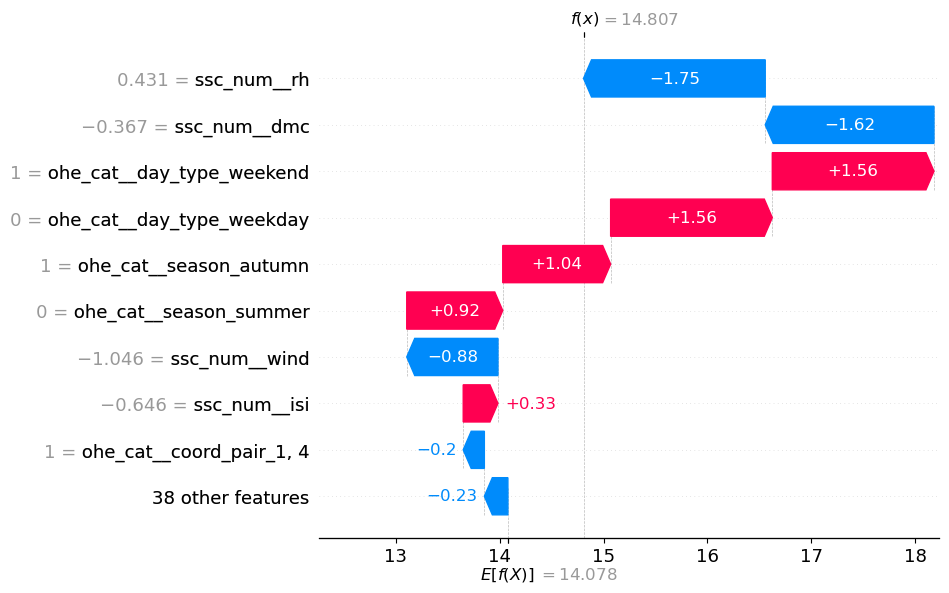

In [31]:
best_pipeline = res_grid_A.best_estimator_

best_coltrans = best_pipeline.named_steps['preprocessing']

feature_names = best_coltrans.get_feature_names_out()

features_test_TX = best_coltrans.transform(features_test)

best_model = best_pipeline.named_steps['regressor']

explainer_test = shap.LinearExplainer(best_model, features_test_TX, feature_names = feature_names)

shap_values_test = explainer_test(features_test_TX)

shap.plots.waterfall(shap_values_test[88])

> For observation 88, the model predicted a burned area (14.807), which is a bit higher than the average (14.078).<br> 
>
> Out of all the features (see above figure), relative humidity (ssc_num_rh) had the biggest impact (negative contribution) on this prediction.

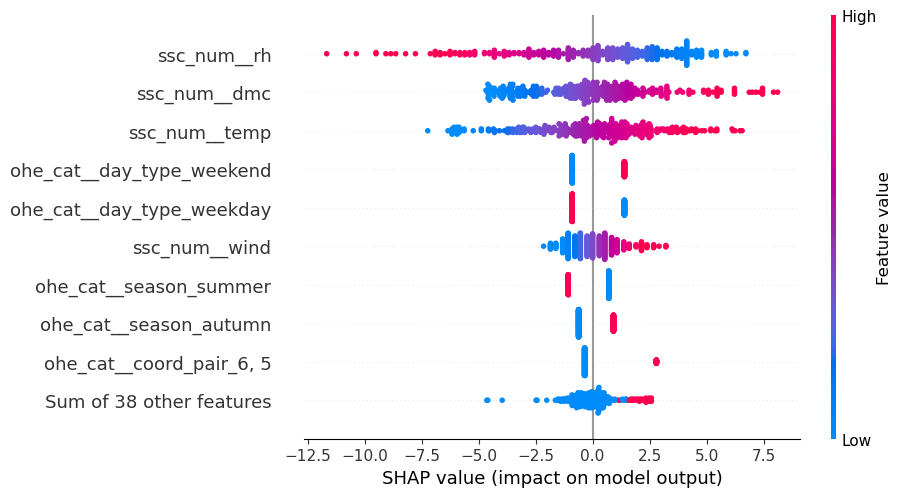

In [32]:
features_train_TX = best_coltrans.transform(features_train)

explainer_train = shap.LinearExplainer(best_model, features_train_TX, feature_names = feature_names)

shap_values_train = explainer_train(features_train_TX)

shap.plots.beeswarm(shap_values_train)

In [33]:
pd.DataFrame({'Feature': feature_names, 'Importance': np.abs(shap_values_train.values).mean(axis=0)}).sort_values('Importance', ascending=False)

,Feature,Importance
5,ssc_num__rh,2.885875
1,ssc_num__dmc,2.139964
4,ssc_num__temp,2.099494
46,ohe_cat__day_type_weekend,1.071570
45,ohe_cat__day_type_weekday,1.071570
6,ssc_num__wind,0.874695
43,ohe_cat__season_summer,0.861934
41,ohe_cat__season_autumn,0.724723
29,"ohe_cat__coord_pair_6, 5",0.617697
37,"ohe_cat__coord_pair_8, 6",0.346679


> According to the above table:<br>
>
> The most important feature: relative humidity.<br> 
>
> The least important feature: the spatial coordinates, for example, the variable ohe_cat__coord_pair_5,5. In general, the coordinate variables don't seem to add much value for predicting the outcome, since almost all of their one-hot encoded variables rank among the least important.

> Based on the SHAP values, I would consider removing spatial coordinate features, since they add very little to the model's predictions.<br> 
>
> To check their impact, I would retrain the model and compare performance before and after removing them (could set up different pipelines).<br> 
>
> If the performance metric stays the same (or even improves), that would confirm those features were not helping a lot.

## Criteria

The [rubric](./assignment_2_rubric_clean.xlsx) contains the criteria for assessment.

## Submission Information

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.

### Submission Parameters:
* Submission Due Date: `HH:MM AM/PM - DD/MM/YYYY`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb) should be populated and should be the only change in your pull request.
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/production/pull/<pr_id>`
    * Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.

Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.

If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at the `help` channel. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.

# Reference

Cortez,Paulo and Morais,Anbal. (2008). Forest Fires. UCI Machine Learning Repository. https://doi.org/10.24432/C5D88D.